## 1. Modificación y ejecución del presupuesto

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from src.config import DATA_PROCESSED

pd.set_option("display.float_format", "{:,.1f}".format)



In [2]:
ancho = pd.read_parquet(DATA_PROCESSED / "panel_ancho.parquet")
ancho.shape

(11, 60)

- El saldo inicial de caja se presupuesta en 0 o 1 (M$) y se incorpora durante el año mediante modificación presupuestaria. Parte del crecimiento del presupuesto vigente corresponde a ese saldo, no a recursos nuevos.

In [3]:
cols = [
    "nombre_municipio",
    "anio",
    "ppto_inicial_gastos",
    "ppto_vigente_gastos",
    "gasto_devengado",
    "ppto_inicial_ingresos",
    "ppto_inicial_saldo_caja",
    "ppto_vigente_saldo_caja",
    "pct_ejecucion_sinim",

]
ppto = ancho[cols].copy()
ppto

,nombre_municipio,anio,ppto_inicial_gastos,ppto_vigente_gastos,gasto_devengado,ppto_inicial_ingresos,ppto_inicial_saldo_caja,ppto_vigente_saldo_caja,pct_ejecucion_sinim
0,TALCAHUANO,2015,"38,796,896.0","54,702,594.0","36,940,740.0","38,796,896.0",0.0,"4,191,696.0",67.5
1,TALCAHUANO,2016,"40,690,429.0","55,209,063.0","42,691,865.0","40,690,429.0",0.0,"6,744,060.0",77.3
2,TALCAHUANO,2017,"39,121,838.0","53,008,445.0","41,771,999.0","39,121,838.0",0.0,"6,696,879.0",78.8
3,TALCAHUANO,2018,"38,436,410.0","54,614,448.0","45,727,037.0","40,463,894.0",0.0,"6,813,770.0",83.7
4,TALCAHUANO,2019,"41,683,713.0","51,481,511.0","45,379,258.0","41,683,713.0",1.0,"4,130,983.0",88.2
5,TALCAHUANO,2020,"44,170,709.0","52,071,521.0","40,264,324.0","44,170,709.0",0.0,"4,165,319.0",77.3
6,TALCAHUANO,2021,"42,113,403.0","48,130,734.0","41,024,507.0","42,113,403.0",1.0,"2,826,968.0",85.2
7,TALCAHUANO,2022,"34,130,318.0","46,734,925.0","40,084,009.0","34,130,318.0",1.0,"3,697,044.0",85.8
8,TALCAHUANO,2023,"42,901,043.0","55,068,434.0","45,861,201.0","42,901,043.0",1.0,"6,517,838.0",83.3
9,TALCAHUANO,2024,"53,004,457.0","65,144,997.0","55,053,669.0","53,004,457.0",1.0,"8,459,670.0",84.5


### talcahuano
- 2022: el presupuesto inicial cayó a 34,1 mil millones (vs. ~42 en 2021 y 2023), lo que eleva el % de modificación a 36,9%. Hipótesis: estimación conservadora de ingresos por la pandemia o cambio de administración tras las elecciones de 2021. Verificar comparando con otras comunas.

In [4]:
# % de crecimiento del presupuesto vigente respecto al inicial, dentro de cada año

ppto["pct_modificacion"] = (ppto["ppto_vigente_gastos"] / ppto["ppto_inicial_gastos"] - 1) * 100

ppto[["anio", "pct_modificacion"]]

,anio,pct_modificacion
0,2015,41.0
1,2016,35.7
2,2017,35.5
3,2018,42.1
4,2019,23.5
5,2020,17.9
6,2021,14.3
7,2022,36.9
8,2023,28.4
9,2024,22.9


In [5]:
# % del presupuesto vigente que se devengó en el año
#**Gasto devengado:** gasto reconocido contablemente en el momento en que el municipio recibe el bien o servicio y nace la obligación de pagarlo, aunque el pago se realice después.

ppto["pct_ejecucion"] = ppto["gasto_devengado"] / ppto["ppto_vigente_gastos"] * 100
ppto[["anio", "pct_modificacion", "pct_ejecucion"]]

,anio,pct_modificacion,pct_ejecucion
0,2015,41.0,67.5
1,2016,35.7,77.3
2,2017,35.5,78.8
3,2018,42.1,83.7
4,2019,23.5,88.1
5,2020,17.9,77.3
6,2021,14.3,85.2
7,2022,36.9,85.8
8,2023,28.4,83.3
9,2024,22.9,84.5


In [6]:
diferencia = (ppto["pct_ejecucion"] - ppto["pct_ejecucion_sinim"]).abs()
print("Diferencia máxima con SINIM:", diferencia.max().round(2))

ppto[diferencia > 0.2]   # filas que no coinciden, si las hay

Diferencia máxima con SINIM: 0.0


,nombre_municipio,anio,ppto_inicial_gastos,ppto_vigente_gastos,gasto_devengado,ppto_inicial_ingresos,ppto_inicial_saldo_caja,ppto_vigente_saldo_caja,pct_ejecucion_sinim,pct_modificacion,pct_ejecucion


In [7]:
ppto

,nombre_municipio,anio,ppto_inicial_gastos,ppto_vigente_gastos,gasto_devengado,ppto_inicial_ingresos,ppto_inicial_saldo_caja,ppto_vigente_saldo_caja,pct_ejecucion_sinim,pct_modificacion,pct_ejecucion
0,TALCAHUANO,2015,"38,796,896.0","54,702,594.0","36,940,740.0","38,796,896.0",0.0,"4,191,696.0",67.5,41.0,67.5
1,TALCAHUANO,2016,"40,690,429.0","55,209,063.0","42,691,865.0","40,690,429.0",0.0,"6,744,060.0",77.3,35.7,77.3
2,TALCAHUANO,2017,"39,121,838.0","53,008,445.0","41,771,999.0","39,121,838.0",0.0,"6,696,879.0",78.8,35.5,78.8
3,TALCAHUANO,2018,"38,436,410.0","54,614,448.0","45,727,037.0","40,463,894.0",0.0,"6,813,770.0",83.7,42.1,83.7
4,TALCAHUANO,2019,"41,683,713.0","51,481,511.0","45,379,258.0","41,683,713.0",1.0,"4,130,983.0",88.2,23.5,88.1
5,TALCAHUANO,2020,"44,170,709.0","52,071,521.0","40,264,324.0","44,170,709.0",0.0,"4,165,319.0",77.3,17.9,77.3
6,TALCAHUANO,2021,"42,113,403.0","48,130,734.0","41,024,507.0","42,113,403.0",1.0,"2,826,968.0",85.2,14.3,85.2
7,TALCAHUANO,2022,"34,130,318.0","46,734,925.0","40,084,009.0","34,130,318.0",1.0,"3,697,044.0",85.8,36.9,85.8
8,TALCAHUANO,2023,"42,901,043.0","55,068,434.0","45,861,201.0","42,901,043.0",1.0,"6,517,838.0",83.3,28.4,83.3
9,TALCAHUANO,2024,"53,004,457.0","65,144,997.0","55,053,669.0","53,004,457.0",1.0,"8,459,670.0",84.5,22.9,84.5


## 2. Evolución de la modificación y la ejecución

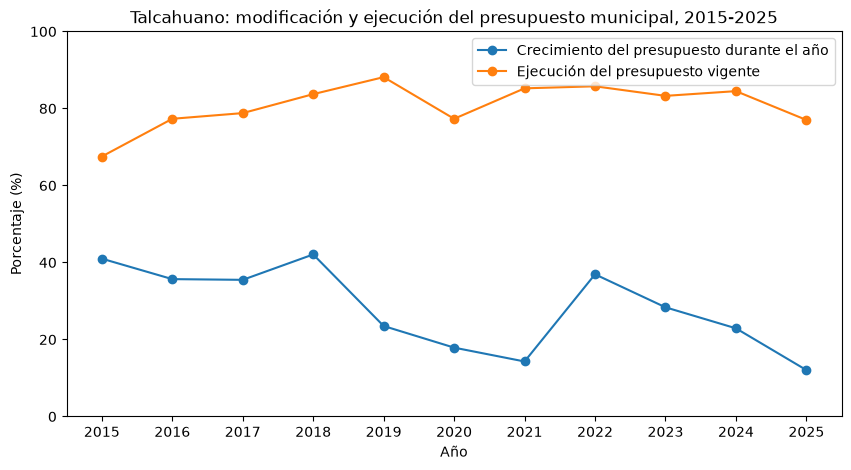

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(ppto["anio"], ppto["pct_modificacion"], marker="o", label="Crecimiento del presupuesto durante el año")
ax.plot(ppto["anio"], ppto["pct_ejecucion"], marker="o", label="Ejecución del presupuesto vigente")

ax.set_title("Talcahuano: modificación y ejecución del presupuesto municipal, 2015-2025")
ax.set_xlabel("Año")
ax.set_ylabel("Porcentaje (%)")
ax.set_xticks(ppto["anio"])
ax.set_ylim(0, 100)
ax.legend()
plt.show()

In [12]:
# % del presupuesto inicial que representa el gasto devengado
ppto["pct_devengado_vs_inicial"] = ppto["gasto_devengado"] / ppto["ppto_inicial_gastos"] * 100
ppto[["anio", "pct_devengado_vs_inicial", "pct_ejecucion"]]

,anio,pct_devengado_vs_inicial,pct_ejecucion
0,2015,95.2,67.5
1,2016,104.9,77.3
2,2017,106.8,78.8
3,2018,119.0,83.7
4,2019,108.9,88.1
5,2020,91.2,77.3
6,2021,97.4,85.2
7,2022,117.4,85.8
8,2023,106.9,83.3
9,2024,103.9,84.5
